# 03. 기본 EDA — 변수 분포·시간 추이·제품 비교·불량 미리보기

**목적**: 가설 검증(B) 전에 데이터 전체 모습을 한 번에 훑고, 보고서 1장(데이터 이해·진단)에 쓸 그림·표를 만든다.

| 장 | 내용 | 산출물 |
|---|---|---|
| 1 | 데이터 개요 (기간·Run·샷·불량) | `overview.csv` |
| 2 | **변수 해상도·변동 요약표** (IQR 칸 수, 최빈 비율, 이산/중간/연속, Run 간 비중) | `variable_profile.csv` |
| 3 | 결측·이상치 (Run 내 robust \|z\| > 5) | `outlier_counts.csv` |
| 4 | 변수별 분포 (2차 vs 추가, 불량 위치) | `dist_*.png` |
| 5 | 시간 추이 (Run 경계·불량 위치) | `trend_*.png` |
| 6 | 제품 비교 (CN7 vs RG3) | `product_compare.csv` |
| 7 | 상관 구조 (2차 양품, Spearman) | `corr_*.png` |
| 8 | 불량 유형별 분포 미리보기 (B 가설 준비) | `reason_strip_*.png` |

**데이터**: `base/cn7_shots.csv`, `base/rg3_shots.csv` (split `제외` 빼고). 모든 값은 **raw(원래 단위)** 로 본다 — 2차 z는 2차 행 기준이라 추가 기간 비교에 부적합

## 0. 설정·데이터

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap

BASE_DIR = './base'
OUT_DIR = './outputs/eda'
os.makedirs(OUT_DIR, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']

_av = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _av:
        mpl.rcParams['font.family'] = _f; break
mpl.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#6f6e69', 'ytick.color': '#6f6e69'})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

INK = '#2b2a27'
SPLIT_COL = {'2차': '#2a78d6', '추가': '#eb6834'}
REASON_COL = {'정상': '#c3c2b7', '가스': '#e34948', '미성형': '#4a3aa7', '가스+미성형': '#e87ba4', '초기허용불량': '#eda100'}
DIVERGING = LinearSegmentedColormap.from_list('div', ['#184f95', '#6da7ec', '#f0efec', '#ef8a88', '#b52a2a'])
SEQ = LinearSegmentedColormap.from_list('seq', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

D = {}
for p in PRODUCTS:
    df = pd.read_csv(os.path.join(BASE_DIR, f'{p}_shots.csv'), parse_dates=['TimeStamp'])
    D[p] = df[df['split'] != '제외'].sort_values('TimeStamp').reset_index(drop=True)
VARS = [c[:-4] for c in D['cn7'].columns if c.endswith('_raw')]
raw = lambda c: f'{c}_raw'
short = lambda v: (v.replace('Barrel_Temperature_', 'Barrel_').replace('Mold_Temperature_', 'Mold_')
                    .replace('Hopper_Temperature', 'Hopper').replace('Max_', '').replace('Average_', 'Avg_'))
print('공정변수', len(VARS), '개:', VARS)

공정변수 21 개: ['Injection_Time', 'Filling_Time', 'Plasticizing_Time', 'Cycle_Time', 'Clamp_Close_Time', 'Cushion_Position', 'Plasticizing_Position', 'Max_Injection_Speed', 'Max_Screw_RPM', 'Max_Injection_Pressure', 'Max_Switch_Over_Pressure', 'Average_Back_Pressure', 'Barrel_Temperature_1', 'Barrel_Temperature_2', 'Barrel_Temperature_3', 'Barrel_Temperature_4', 'Barrel_Temperature_5', 'Barrel_Temperature_6', 'Hopper_Temperature', 'Mold_Temperature_3', 'Mold_Temperature_4']


## 1. 데이터 개요

In [2]:
rows = []
for p in PRODUCTS:
    for sp, g in D[p].groupby('split'):
        rows.append({'제품': p.upper(), 'split': sp, '기간': f"{g['TimeStamp'].min():%m-%d} ~ {g['TimeStamp'].max():%m-%d}",
                     'Run': g['run_id'].nunique(), '샷': len(g), '불량 샷': int(g['PassOrFail'].sum()),
                     '불량률': g['PassOrFail'].mean(),
                     **{t: int((g['Reason'] == t).sum()) for t in ['가스', '미성형', '가스+미성형', '초기허용불량']},
                     'LH 불량': int(g['LH_fail'].fillna(0).sum()), 'RH 불량': int(g['RH_fail'].fillna(0).sum())})
OVERVIEW = pd.DataFrame(rows)
display(OVERVIEW.style.format({'불량률': '{:.1%}'}))

,제품,split,기간,Run,샷,불량 샷,불량률,가스,미성형,가스+미성형,초기허용불량,LH 불량,RH 불량
0,CN7,2차,10-16 ~ 10-20,2,606,14,2.3%,11,1,2,0,4,13
1,CN7,추가,10-27 ~ 11-03,4,1373,6,0.4%,0,1,0,5,6,5
2,RG3,2차,10-21 ~ 10-23,5,591,25,4.2%,17,8,0,0,0,25
3,RG3,추가,11-04 ~ 11-04,1,36,7,19.4%,5,2,0,0,5,2


## 2. 변수 해상도·변동 요약표

모든 변수가 고정 해상도(0.01 또는 0.1)로 기록돼서 엄밀히는 전부 이산값이다. 그래서 **고유값 개수가 아니라 "변동폭이 기록 단위 몇 칸인지"** 로 성격을 나눈다 (2차 기준).

| 분류 | 기준 | 다루는 법 |
|---|---|---|
| 상수·이산 | IQR ≤ 2칸 또는 최빈값 ≥ 50% | 상관·분포 해석 보류, 모델은 제외 또는 범주형 |
| 중간 | IQR 3~5칸 | 계단형 주의, robust z 분모에 해상도 하한 |
| 연속형에 가까움 | IQR ≥ 6칸 | 상관·분포 분석 가능 |

`Run 간 비중 η²` ≥ 0.5면 연속형이어도 샷 신호가 아니라 **Run 단위 신호**로 해석

In [3]:
def resolution(x):
    u = np.sort(pd.unique(x.dropna().round(6)))
    d = np.diff(u)
    return d[d > 0].min() if (d > 0).any() else 0.0

def eta2(df, col):
    x = df[col]; tot = ((x - x.mean()) ** 2).sum()
    return np.nan if tot == 0 else ((df.groupby('run_id')[col].transform('mean') - x.mean()) ** 2).sum() / tot

def classify(steps, mode):
    if steps <= 2 or mode >= 0.5:
        return '상수·이산'
    return '중간' if steps <= 5 else '연속형'

rows = []
for p in PRODUCTS:
    s = D[p][D[p]['split'] == '2차']
    for v in VARS:
        x = s[raw(v)]
        step = resolution(D[p][raw(v)])
        iqr = x.quantile(.75) - x.quantile(.25)
        steps = round(iqr / step, 1) if step > 0 else 0
        mode = x.round(6).value_counts(normalize=True).iloc[0]
        rows.append({'제품': p.upper(), '변수': v, '해상도': step, '고유값 수': x.round(6).nunique(),
                     '중앙값': x.median(), '최소': x.min(), '최대': x.max(), 'IQR': iqr, 'IQR 칸 수': steps,
                     '최빈 비율': mode, 'Run 간 비중 η²': eta2(s, raw(v)), '분류': classify(steps, mode)})
PROFILE = pd.DataFrame(rows)
for p in PRODUCTS:
    print(f'===== {p.upper()} (2차)')
    t = PROFILE[PROFILE['제품'] == p.upper()].drop(columns='제품').set_index('변수')
    display(t.style.format({'해상도': '{:g}', '중앙값': '{:.2f}', '최소': '{:.2f}', '최대': '{:.2f}', 'IQR': '{:.2f}',
                            '최빈 비율': '{:.0%}', 'Run 간 비중 η²': '{:.2f}'}, na_rep='-'))

# 제품별 분류 비교
CMP = PROFILE.pivot(index='변수', columns='제품', values='분류')
CMP['제품마다 다름'] = np.where(CMP['CN7'] != CMP['RG3'], '⚠️', '')
display(CMP)

===== CN7 (2차)


,해상도,고유값 수,중앙값,최소,최대,IQR,IQR 칸 수,최빈 비율,Run 간 비중 η²,분류
변수,,,,,,,,,,
Injection_Time,0.01,15,9.54,9.36,9.60,0.04,4.000000,20%,0.52,중간
Filling_Time,0.01,14,4.43,4.24,4.49,0.03,3.000000,19%,0.50,중간
Plasticizing_Time,0.009998,34,17.01,16.87,21.10,0.12,12.000000,7%,0.10,연속형
Cycle_Time,0.009998,13,59.52,59.36,60.00,0.04,4.000000,54%,0.20,상수·이산
Clamp_Close_Time,0.01,3,7.12,7.12,7.14,0.01,1.000000,54%,0.00,상수·이산
Cushion_Position,0.009949,5,653.41,653.40,653.45,0.01,1.000000,63%,0.21,상수·이산
Plasticizing_Position,0.009994,13,68.49,68.12,68.86,0.36,36.000000,29%,0.99,연속형
Max_Injection_Speed,0.099998,20,56.00,55.20,60.90,0.50,5.000000,16%,0.23,중간
Max_Screw_RPM,0.099998,8,30.80,30.50,31.20,0.20,2.000000,34%,0.05,상수·이산


===== RG3 (2차)


,해상도,고유값 수,중앙값,최소,최대,IQR,IQR 칸 수,최빈 비율,Run 간 비중 η²,분류
변수,,,,,,,,,,
Injection_Time,0.01,3,1.06,1.05,1.07,0.00,0.000000,99%,0.03,상수·이산
Filling_Time,0.01,2,0.94,0.93,0.94,0.01,1.000000,59%,0.33,상수·이산
Plasticizing_Time,0.01,27,12.92,12.80,13.09,0.06,6.000000,10%,0.49,연속형
Cycle_Time,0.009998,10,61.78,61.72,62.20,0.02,2.000000,63%,0.01,상수·이산
Clamp_Close_Time,0.01,3,6.80,6.79,6.81,0.01,1.000000,43%,0.82,상수·이산
Cushion_Position,0.009949,7,654.25,654.23,654.29,0.02,2.000000,28%,0.41,상수·이산
Plasticizing_Position,0.009998,8,53.58,53.55,53.62,0.02,2.000000,30%,0.51,상수·이산
Max_Injection_Speed,0.099991,7,128.20,127.90,128.50,0.20,2.000000,27%,0.63,상수·이산
Max_Screw_RPM,0.099998,4,30.80,30.70,31.00,0.10,1.000000,43%,0.01,상수·이산


제품,CN7,RG3,제품마다 다름
변수,,,
Average_Back_Pressure,중간,연속형,⚠️
Barrel_Temperature_1,연속형,중간,⚠️
Barrel_Temperature_2,중간,연속형,⚠️
Barrel_Temperature_3,중간,중간,
Barrel_Temperature_4,연속형,연속형,
Barrel_Temperature_5,중간,중간,
Barrel_Temperature_6,중간,중간,
Clamp_Close_Time,상수·이산,상수·이산,
Cushion_Position,상수·이산,상수·이산,


## 3. 결측·이상치

- 결측: 공정변수 결측 수
- 이상치: **같은 Run 양품 기준 robust z** (분모 하한 = 해상도) \|z\| > 5인 샷 수 → 어느 변수가 가끔 크게 튀는지

In [4]:
def robust_z(df):
    Z = pd.DataFrame(index=df.index, columns=VARS, dtype=float)
    step = {v: resolution(df[raw(v)]) for v in VARS}
    for r, g in df.groupby('run_id'):
        ref = g[g['PassOrFail'] == 0]
        for v in VARS:
            x = ref[raw(v)]; med = x.median()
            scale = max(1.4826 * (x - med).abs().median(), 0.5 * x.std(ddof=0), step[v])
            Z.loc[g.index, v] = (g[raw(v)] - med) / scale if scale > 0 else np.nan
    return Z

Z = {p: robust_z(D[p]) for p in PRODUCTS}
rows = []
for p in PRODUCTS:
    df = D[p]
    for v in VARS:
        out = Z[p][v].abs() > 5
        rows.append({'제품': p.upper(), '변수': v, '결측': int(df[raw(v)].isna().sum()),
                     '이상치(2차)': int((out & (df['split'] == '2차')).sum()),
                     '이상치(추가)': int((out & (df['split'] == '추가')).sum()),
                     '이상치 중 불량': int((out & (df['PassOrFail'] == 1)).sum())})
OUTL = pd.DataFrame(rows)
print('공정변수 결측 총합:', int(OUTL['결측'].sum()))
display(OUTL.pivot(index='변수', columns='제품', values=['이상치(2차)', '이상치(추가)', '이상치 중 불량']))

공정변수 결측 총합: 0


이상치(2차)     이상치(추가)     이상치 중 불량    
제품                           CN7 RG3     CN7 RG3      CN7 RG3
변수                                                           
Average_Back_Pressure          2   0       4   1        3   0
Barrel_Temperature_1           0   0       0   0        0   0
Barrel_Temperature_2           0   0       0   0        0   0
Barrel_Temperature_3           0   1      14   0        0   0
Barrel_Temperature_4           0   0       0   0        0   0
Barrel_Temperature_5           1   0       1   2        0   0
Barrel_Temperature_6           0   0       0   0        0   0
Clamp_Close_Time               0   0       2   0        2   0
Cushion_Position               0   0       1   0        1   0
Cycle_Time                     2   7      16   2        4   1
Filling_Time                   5   0       7   0        8   0
Hopper_Temperature             3   2       0   0        1   0
Injection_Time                 5   0       7   0        8   0
Max_Injection_Pressure         1   0       5   0        4   0
Max_Injection_Speed            6   0       8   0        8   0
Max_Screw_RPM                  0   0       0   0        0   0
Max_Switch_Over_Pressure       2   2       5   1        4   0
Mold_Temperature_3             0   0       0   0        0   0
Mold_Temperature_4             0   0       0   0        0   0
Plasticizing_Position          3   0       1   0        0   0
Plasticizing_Time              3   0       8   0        2   0

## 4. 변수별 분포

- 히스토그램: 2차(파랑) vs 추가(주황), 각 split 안에서 비율로 정규화 (샷 수가 달라서)
- 아래 눈금: 불량 샷 위치 (색 = 불량 유형)
- x축은 1~99% 범위로 잘라 과도구간 극단값 때문에 분포가 뭉개지지 않게 함 (잘린 샷 수는 제목에 표시)

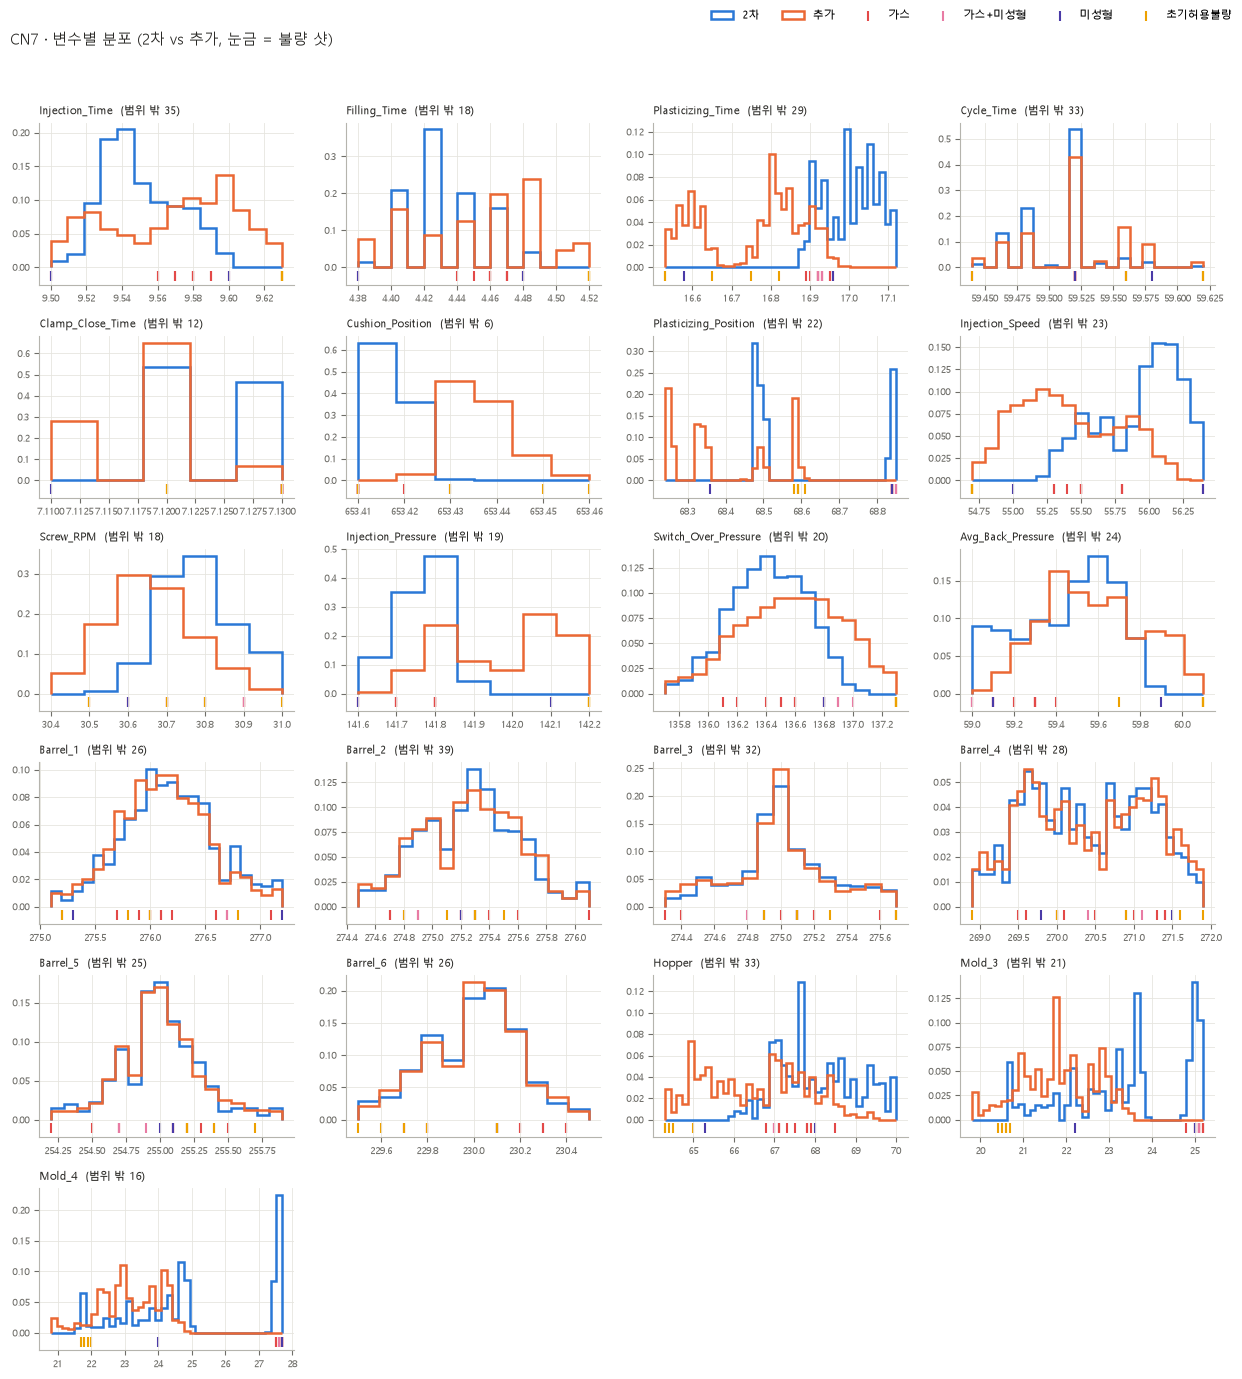

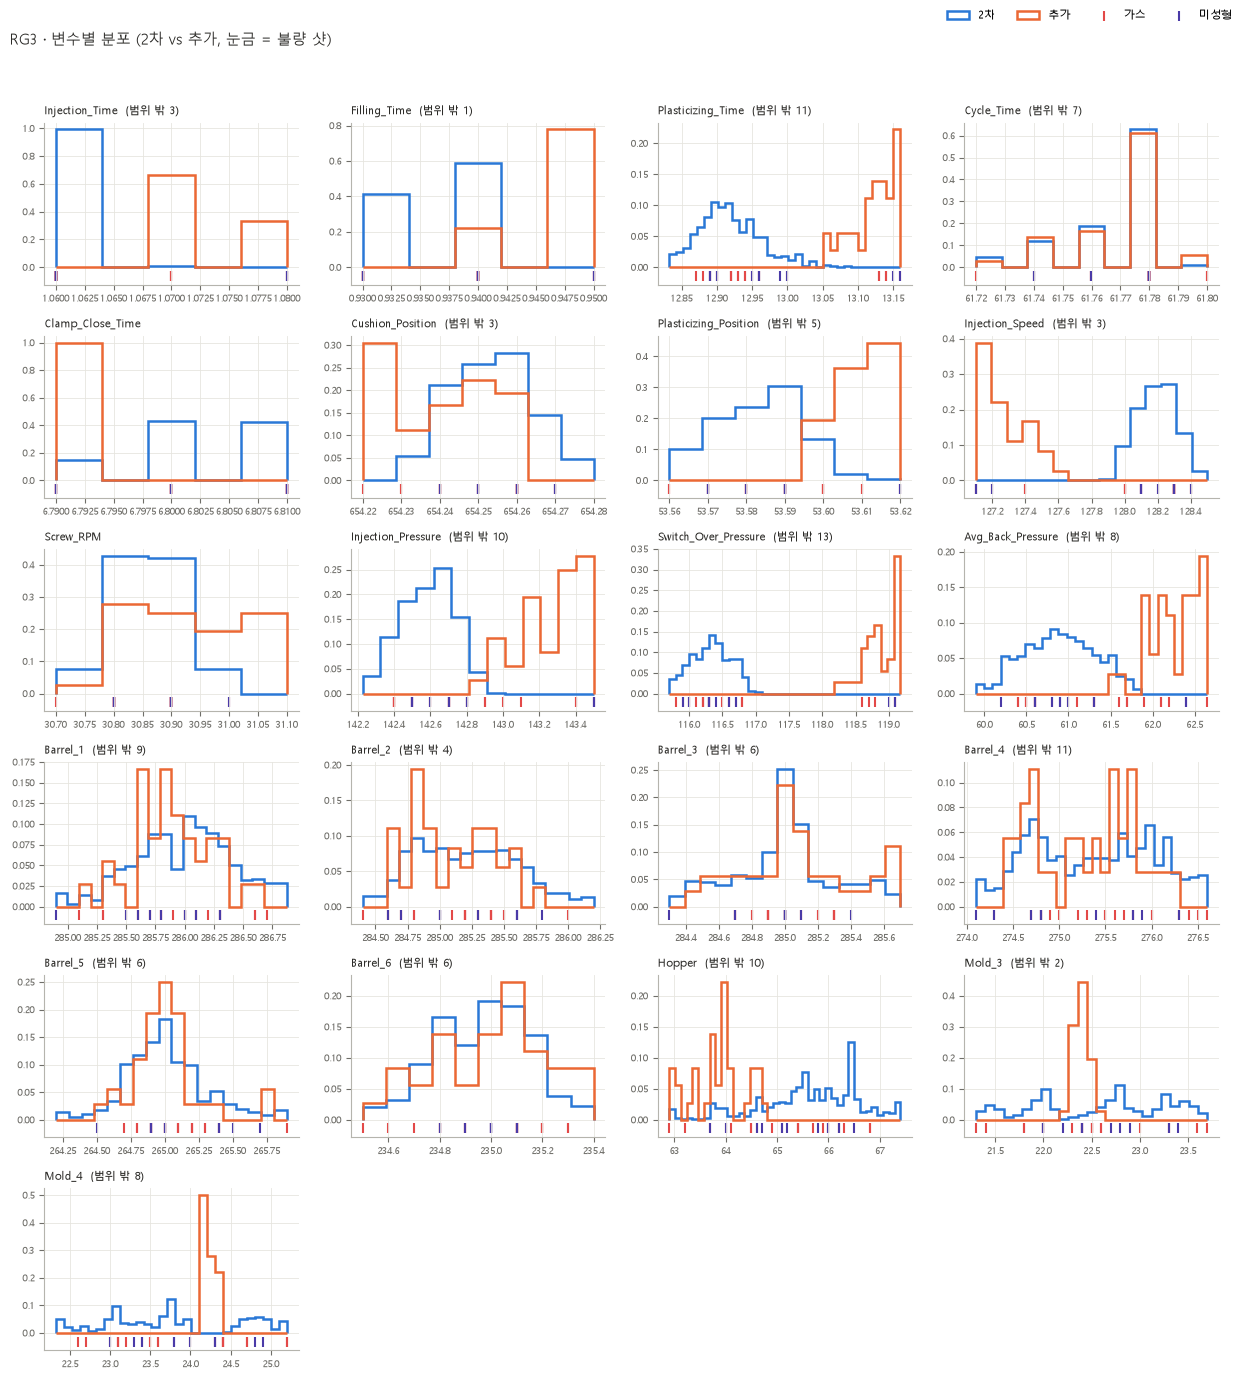

In [5]:
def dist_grid(p, ncol=4):
    df = D[p]
    nrow = int(np.ceil(len(VARS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 2.3 * nrow))
    for ax, v in zip(axes.ravel(), VARS):
        x = df[raw(v)]
        lo, hi = x.quantile(0.01), x.quantile(0.99)
        if lo == hi:
            lo, hi = x.min() - 0.5, x.max() + 0.5
        step = resolution(x)
        nb = int(np.clip((hi - lo) / step + 1, 5, 40)) if step > 0 else 10
        bins = np.linspace(lo, hi, nb + 1)
        for sp, g in df.groupby('split'):
            gx = g[raw(v)].clip(lo, hi)
            ax.hist(gx, bins=bins, weights=np.ones(len(gx)) / len(gx), histtype='step', lw=1.8, color=SPLIT_COL[sp], label=sp)
        ymax = ax.get_ylim()[1]
        for rs, g in df[df['PassOrFail'] == 1].groupby('Reason'):
            ax.scatter(g[raw(v)].clip(lo, hi), np.full(len(g), -0.06 * ymax), marker='|', s=60, color=REASON_COL[rs], label=rs)
        clipped = int(((x < lo) | (x > hi)).sum())
        ax.set_title(f"{short(v)}" + (f"  (범위 밖 {clipped})" if clipped else ''), loc='left', fontsize=8, color=INK)
        ax.tick_params(labelsize=6.5); ax.ticklabel_format(useOffset=False, style='plain', axis='x')
        ax.set_ylim(-0.12 * ymax, ymax)
    for ax in axes.ravel()[len(VARS):]:
        ax.axis('off')
    h, l = axes.ravel()[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper right', ncol=6, fontsize=8, frameon=False)
    fig.suptitle(f'{p.upper()} · 변수별 분포 (2차 vs 추가, 눈금 = 불량 샷)', x=0.01, ha='left', fontsize=11, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    return fig

for p in PRODUCTS:
    fig = dist_grid(p)
    fig.savefig(os.path.join(OUT_DIR, f'dist_{p}.png'), dpi=120, bbox_inches='tight'); plt.show()

## 5. 시간 추이

- x = 샷 순서(시간순, Run 사이 정지는 압축), 세로 회색선 = Run 경계, 배경색 = split
- 점 = 샷(회색), 불량 샷은 유형 색으로 강조
- 변수: Run 성격 변수(금형·호퍼 온도), 사출 계열(속도·압력·충전), 계량(계량시간·위치), 쿠션

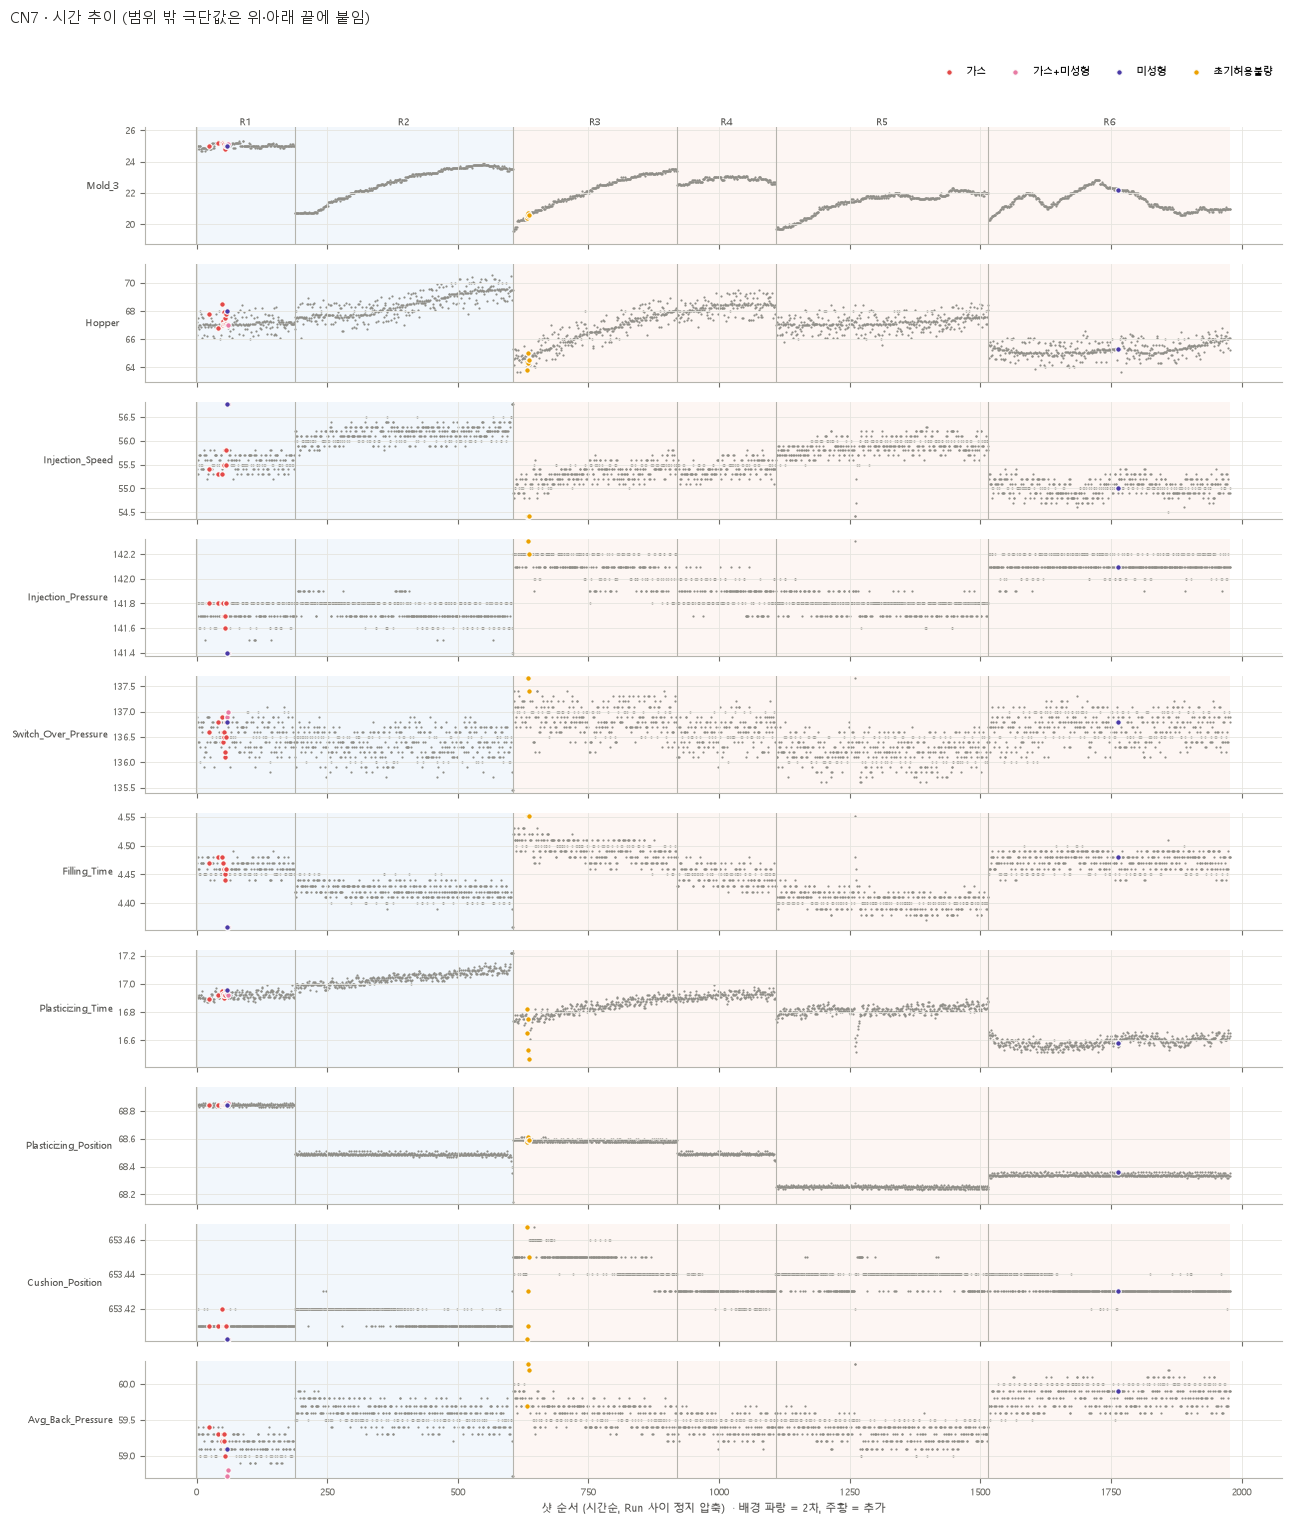

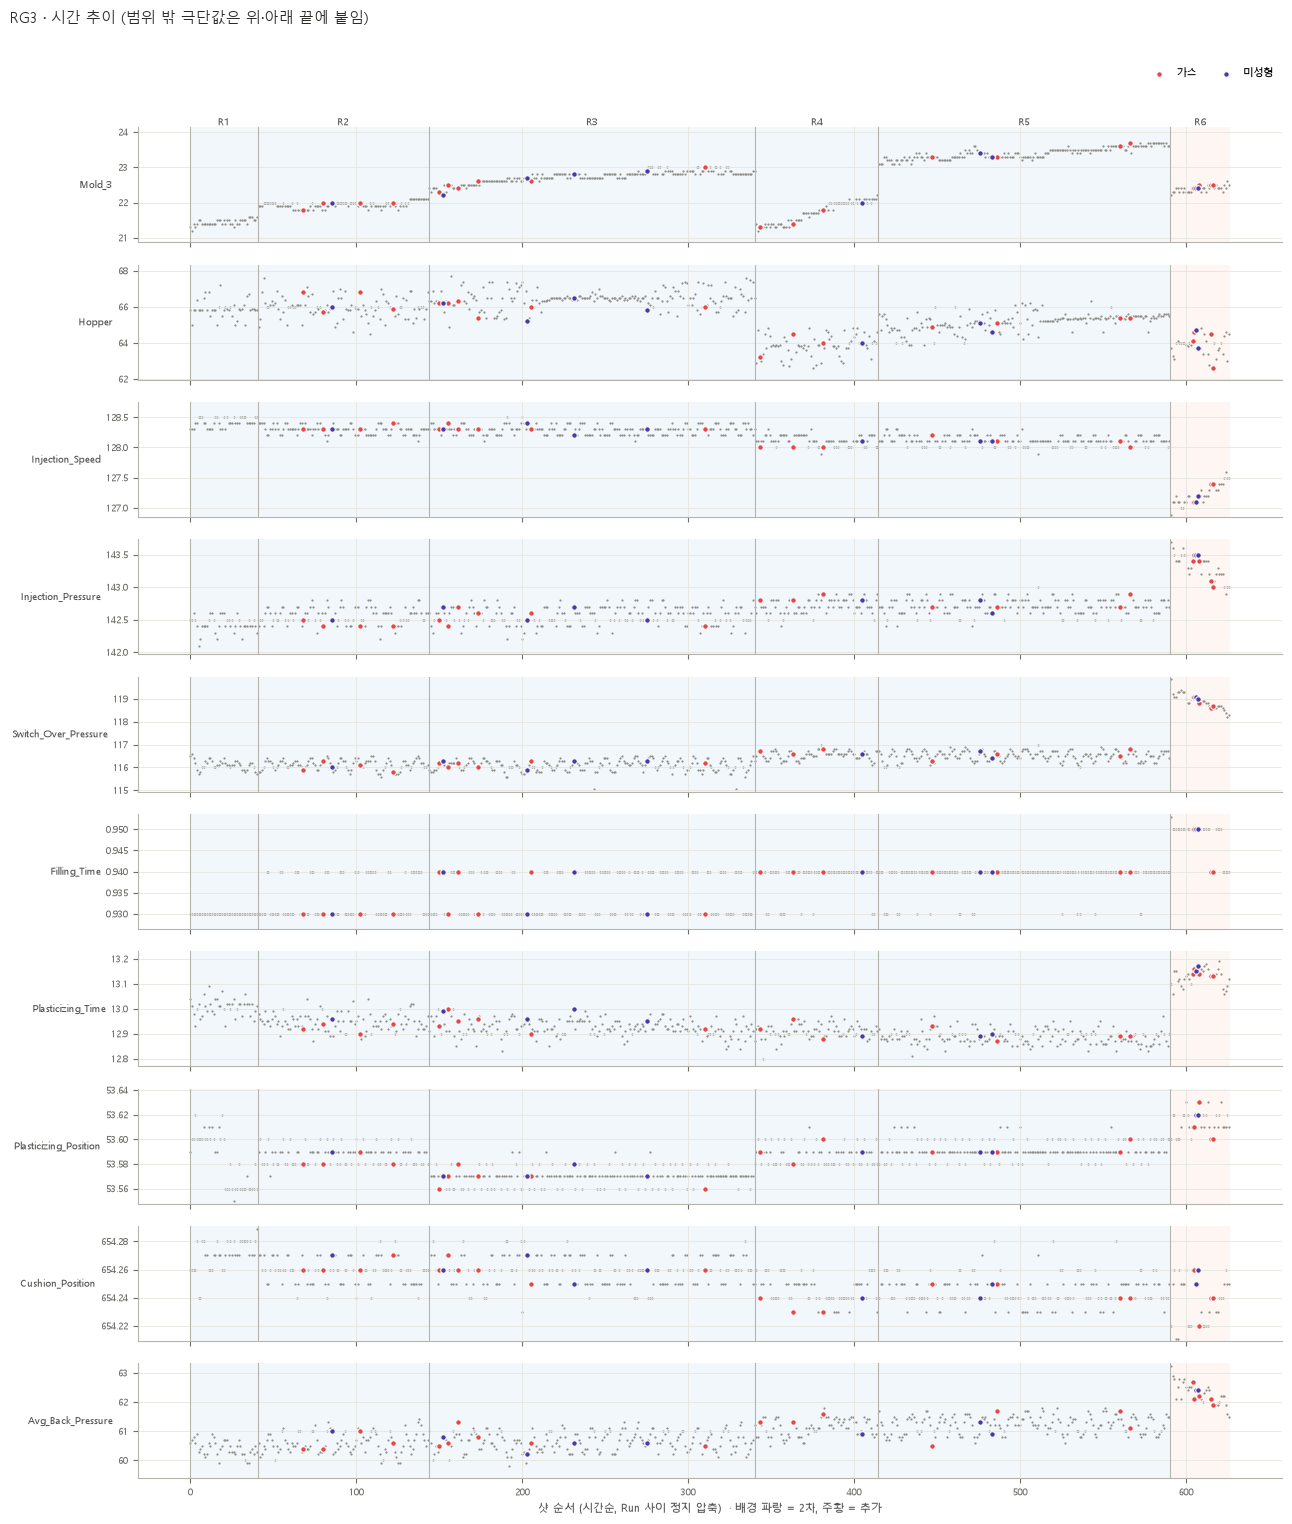

In [6]:
TREND_VARS = ['Mold_Temperature_3', 'Hopper_Temperature', 'Max_Injection_Speed', 'Max_Injection_Pressure',
              'Max_Switch_Over_Pressure', 'Filling_Time', 'Plasticizing_Time', 'Plasticizing_Position', 'Cushion_Position',
              'Average_Back_Pressure']

def trend(p):
    df = D[p].copy()
    df['i'] = np.arange(len(df))
    fig, axes = plt.subplots(len(TREND_VARS), 1, figsize=(13, 1.55 * len(TREND_VARS)), sharex=True)
    bounds = df.groupby('run_id', sort=False)['i'].agg(['min', 'max'])
    for ax, v in zip(axes, TREND_VARS):
        x = df[raw(v)]
        lo, hi = x.quantile(0.005), x.quantile(0.995)
        pad = (hi - lo) * 0.15 or 0.5
        for r, (a, b) in bounds.iterrows():
            sp = df.loc[a, 'split']
            ax.axvspan(a - 0.5, b + 0.5, color=SPLIT_COL[sp], alpha=0.06, lw=0)
            ax.axvline(a - 0.5, color='#b5b4ad', lw=0.8)
        ok = df['PassOrFail'] == 0
        ax.scatter(df.loc[ok, 'i'], x[ok].clip(lo - pad, hi + pad), s=2.5, color='#8f8e88', lw=0)
        for rs, g in df[~ok].groupby('Reason'):
            ax.scatter(g['i'], g[raw(v)].clip(lo - pad, hi + pad), s=16, color=REASON_COL[rs], edgecolors='#fcfcfb', linewidths=0.8,
                       label=rs, zorder=3)
        ax.set_ylim(lo - pad * 1.2, hi + pad * 1.2)
        ax.set_ylabel(short(v), fontsize=7.5, rotation=0, ha='right', va='center'); ax.tick_params(labelsize=6.5)
        ax.ticklabel_format(useOffset=False, style='plain', axis='y')
    for r, (a, b) in bounds.iterrows():
        axes[0].text((a + b) / 2, axes[0].get_ylim()[1], r.split('_')[1], ha='center', va='bottom', fontsize=7.5, color='#52514e')
    axes[0].legend(fontsize=7, frameon=False, ncol=5, loc='upper right', bbox_to_anchor=(1, 1.6))
    axes[-1].set_xlabel('샷 순서 (시간순, Run 사이 정지 압축)  · 배경 파랑 = 2차, 주황 = 추가', fontsize=8)
    fig.suptitle(f'{p.upper()} · 시간 추이 (범위 밖 극단값은 위·아래 끝에 붙임)', x=0.01, ha='left', fontsize=11, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig

for p in PRODUCTS:
    fig = trend(p)
    fig.savefig(os.path.join(OUT_DIR, f'trend_{p}.png'), dpi=120, bbox_inches='tight'); plt.show()

## 6. 제품 비교 (CN7 vs RG3, 2차 양품 중앙값)

두 제품은 같은 설비(650톤)지만 레시피가 완전히 다르다 → **제품별로 따로 분석·모델링**(가설 C5)의 근거

In [7]:
rows = []
for v in VARS:
    a = D['cn7'].query("split == '2차' and PassOrFail == 0")[raw(v)]
    b = D['rg3'].query("split == '2차' and PassOrFail == 0")[raw(v)]
    pooled = np.sqrt((a.var() + b.var()) / 2)
    rows.append({'변수': v, 'CN7 중앙값': a.median(), 'RG3 중앙값': b.median(), 'RG3/CN7': b.median() / a.median() if a.median() else np.nan,
                 '차이 ÷ 샷 변동(표준편차)': (b.median() - a.median()) / pooled if pooled > 0 else np.nan})
CMPP = pd.DataFrame(rows).set_index('변수')
display(CMPP.style.format({'CN7 중앙값': '{:.2f}', 'RG3 중앙값': '{:.2f}', 'RG3/CN7': '{:.2f}', '차이 ÷ 샷 변동(표준편차)': '{:+.0f}'}, na_rep='-'))

,CN7 중앙값,RG3 중앙값,RG3/CN7,차이 ÷ 샷 변동(표준편차)
변수,,,,
Injection_Time,9.54,1.06,0.11,-503
Filling_Time,4.43,0.94,0.21,-204
Plasticizing_Time,17.01,12.92,0.76,-27
Cycle_Time,59.52,61.78,1.04,+59
Clamp_Close_Time,7.12,6.80,0.96,-51
Cushion_Position,653.41,654.25,1.00,+87
Plasticizing_Position,68.49,53.58,0.78,-129
Max_Injection_Speed,56.00,128.20,2.29,+252
Max_Screw_RPM,30.80,30.80,1.00,+0


## 7. 상관 구조 (2차 양품, Spearman)

- 왼쪽 = 전체 상관, 오른쪽 = Run 내 상관(Run 평균 제거). 둘이 다르면 Run 효과가 섞인 관계
- \|ρ\| ≥ 0.5만 숫자 표시. 상수 변수는 제외

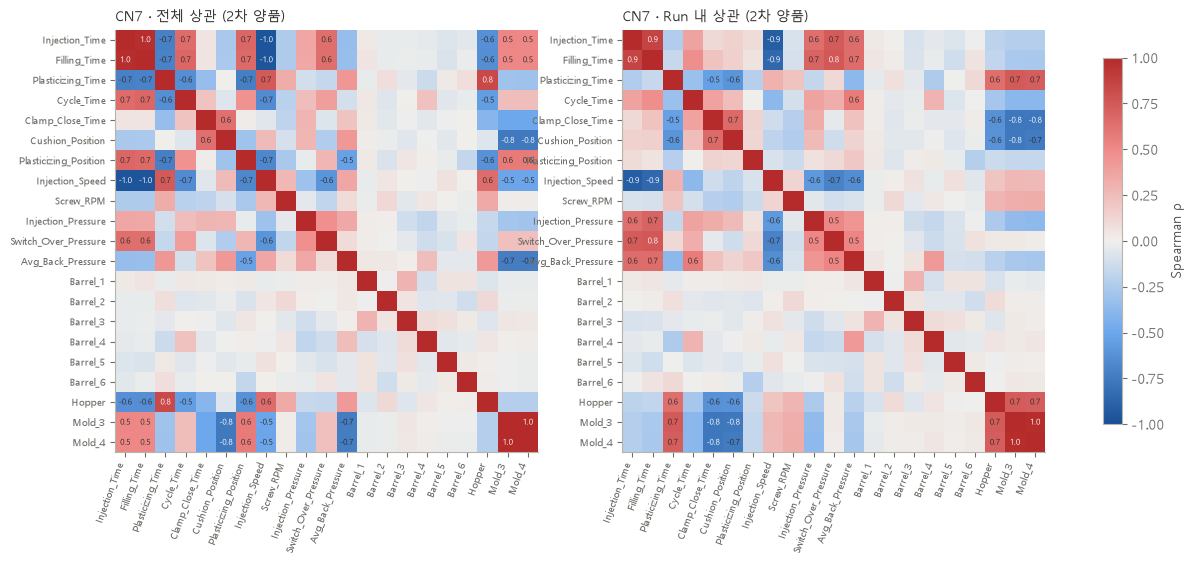

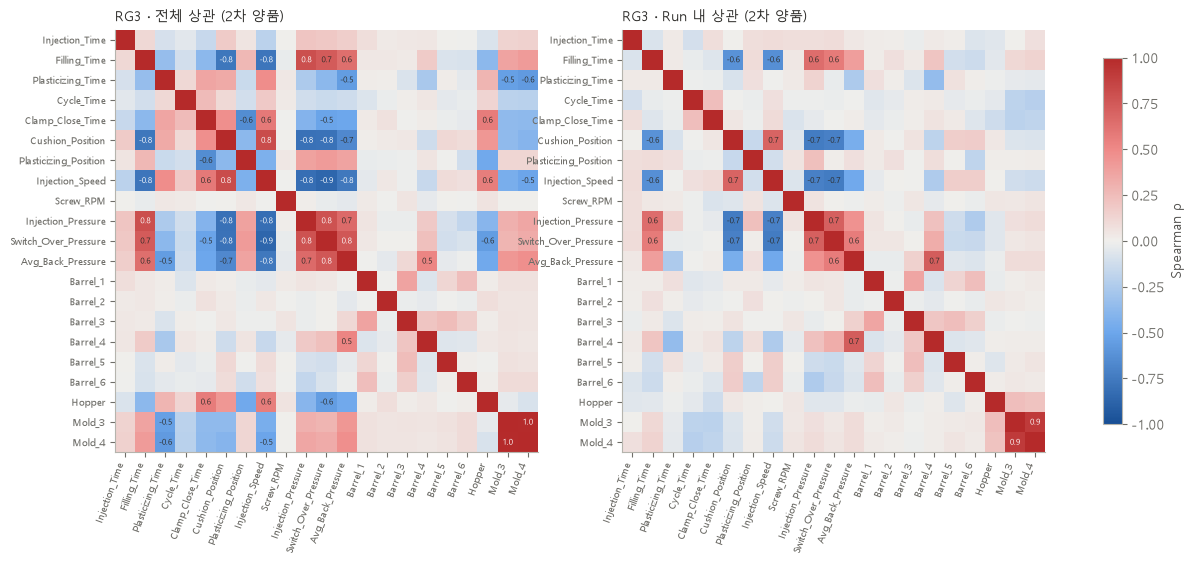

In [8]:
def corr(df, within):
    X = pd.DataFrame({short(v): (df[raw(v)] - df.groupby('run_id')[raw(v)].transform('mean')) if within else df[raw(v)] for v in VARS})
    X = X.loc[:, X.nunique() > 1]
    return X.corr(method='spearman')

for p in PRODUCTS:
    s = D[p].query("split == '2차' and PassOrFail == 0")
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
    for ax, within in zip(axes, [False, True]):
        M = corr(s, within)
        im = ax.imshow(M.values, cmap=DIVERGING, vmin=-1, vmax=1)
        ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, rotation=70, ha='right', fontsize=7)
        ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=7); ax.grid(False)
        for a in range(len(M)):
            for b in range(len(M)):
                v = M.values[a, b]
                if a != b and abs(v) >= 0.5:
                    ax.text(b, a, f'{v:.1f}', ha='center', va='center', fontsize=6, color='#ffffff' if abs(v) >= 0.75 else INK)
        ax.set_title(f"{p.upper()} · {'Run 내' if within else '전체'} 상관 (2차 양품)", loc='left', fontsize=10, color=INK)
    fig.colorbar(im, ax=axes, shrink=0.7, label='Spearman ρ')
    fig.savefig(os.path.join(OUT_DIR, f'corr_{p}.png'), dpi=120, bbox_inches='tight'); plt.show()

## 8. 불량 유형별 분포 미리보기 (B 가설 준비)

- 같은 Run 양품 기준 **robust z** (Run 차이를 뺀 값)를 불량 유형별로 점으로 찍음. 회색 띠 = 양품 중앙 90%
- 어느 유형이 어느 변수에서 양품 띠 밖으로 나가는지 **훑어보기용** (판정은 03에서 하지 않음)

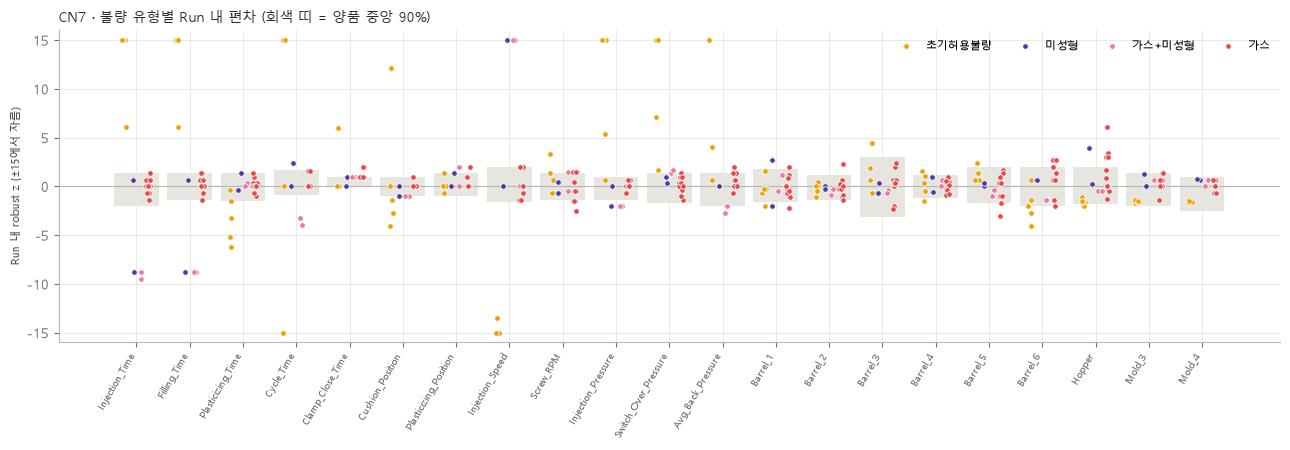

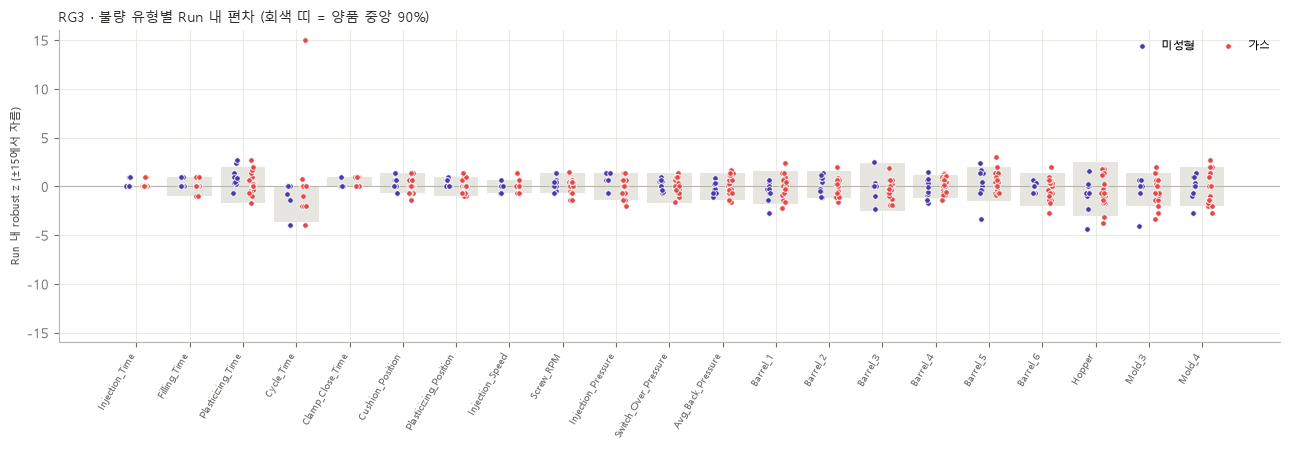

In [9]:
def reason_strip(p):
    df, z = D[p], Z[p]
    types = [t for t in ['정상', '초기허용불량', '미성형', '가스+미성형', '가스'] if (df['Reason'] == t).any()]
    vv = [v for v in VARS if z[v].notna().any() and df[raw(v)].nunique() > 1]
    fig, ax = plt.subplots(figsize=(13, 4.6))
    rng = np.random.default_rng(0)
    for j, v in enumerate(vv):
        ok = df['PassOrFail'] == 0
        lo, hi = z.loc[ok, v].quantile([0.05, 0.95])
        ax.add_patch(plt.Rectangle((j - 0.42, lo), 0.84, hi - lo, color='#e6e5df', lw=0, zorder=0))
        for k, t in enumerate(types[1:]):
            g = z.loc[df['Reason'] == t, v].clip(-15, 15)
            ax.scatter(j - 0.3 + 0.6 * (k + 0.5) / max(len(types) - 1, 1) + rng.uniform(-0.04, 0.04, len(g)), g,
                       s=16, color=REASON_COL[t], edgecolors='#fcfcfb', linewidths=0.6, label=t if j == 0 else None, zorder=3)
    ax.axhline(0, color='#b5b4ad', lw=0.8)
    ax.set_xticks(range(len(vv))); ax.set_xticklabels([short(v) for v in vv], rotation=60, ha='right', fontsize=7.5)
    ax.set_ylabel('Run 내 robust z (±15에서 자름)', fontsize=8); ax.set_ylim(-16, 16)
    ax.legend(fontsize=8, frameon=False, ncol=4, loc='upper right')
    ax.set_title(f'{p.upper()} · 불량 유형별 Run 내 편차 (회색 띠 = 양품 중앙 90%)', loc='left', fontsize=10, color=INK)
    fig.tight_layout()
    return fig

for p in PRODUCTS:
    fig = reason_strip(p)
    fig.savefig(os.path.join(OUT_DIR, f'reason_strip_{p}.png'), dpi=120, bbox_inches='tight'); plt.show()

## 9. 저장

In [10]:
OVERVIEW.to_csv(os.path.join(OUT_DIR, 'overview.csv'), index=False, encoding='utf-8-sig')
PROFILE.to_csv(os.path.join(OUT_DIR, 'variable_profile.csv'), index=False, encoding='utf-8-sig')
OUTL.to_csv(os.path.join(OUT_DIR, 'outlier_counts.csv'), index=False, encoding='utf-8-sig')
CMPP.to_csv(os.path.join(OUT_DIR, 'product_compare.csv'), encoding='utf-8-sig')
print('저장 위치:', os.path.abspath(OUT_DIR))

저장 위치: /tmp/claude-0/-home-claude/b6af321b-f66e-5a8f-868b-d67d3934417c/scratchpad/root/KAMP-IMM/notebooks/outputs/eda


## 읽는 법 · 다음 단계

- **2장 분류표** → 01 노트북 "변동 적음" 판정, B 가설에서 쓸 변수 선택의 기준
- **4장 분포**에서 추가 기간이 2차와 다른 위치에 있으면 → 시점 외 검증 시 드리프트 주의 (예: RG3 11-04)
- **5장 추이**에서 불량이 특정 구간(값의 수준)에 몰려 있으면 → Run 전체 특성형, 점처럼 튀면 → 이벤트형
- **8장**에서 양품 띠 밖으로 나가는 유형·변수 조합 → 04 B 가설 검증의 우선 대상